# 06 · Simulación de producción: construcción de los lotes

**Patrón de despliegue: batch.** La decisión del PSet 1 es mensual: el día 1 de cada mes cobranza recibe la lista priorizada y llama antes del vencimiento. Ver la sección 1 del documento técnico.

**De dónde salen los lotes.** No hay datos posteriores al corte: la fuente UCI termina en septiembre de 2005. Se usa el conjunto de prueba del PSet 3, 6.000 clientes que ningún modelo vio en entrenamiento.
- **Asignación:** se ordenan por `customer_id` y se reparten al azar, con semilla fija, en **10 lotes de 600**.
- **Meses simulados:** los lotes representan oct-2005 a jul-2006.
- **Limitación:** `customer_id` no tiene significado temporal. Los lotes limpios son intercambiables entre sí: miden la variación natural de un lote a otro, no estacionalidad ni tendencia.

**Horizonte.** El target del lote *k* llega con el lote *k+1*: `TARGETS.disponible_en_lote = k + 1`, horizonte de 1 mes. Ningún paso lo usa antes.

**Qué hace este notebook:**
1. Construye los lotes con la deriva inducida y los sube a Snowflake (`PRODUCCION.LOTES` y `PRODUCCION.TARGETS`).
2. Documenta exactamente qué se alteró.
3. Mide el piso de ruido del PSI para justificar los umbrales de alerta.

La simulación en sí la ejecuta Kestra con el flujo `produccion_lotes`.

In [1]:
import sys, json, warnings
sys.path.insert(0, '..'); warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src import almacen, simulacion as sim, produccion
from src.datos import cargar_obt, particion, columnas_features, TARGET, ID
from monitoreo import deriva
print('Almacén:', almacen.modo())
obt, meta = cargar_obt(); train, test = particion(obt); feats = columnas_features(obt)
print(f"OBT {meta['tabla_origen']} | hash {meta['hash_dataset']} | entrenamiento {len(train):,} | prueba {len(test):,}")

Almacén: snowflake


OBT PSET2_MORA.OBT.OBT_CUSTOMER_DEFAULT | hash 372bafd08cb627ae | entrenamiento 24,000 | prueba 6,000


## 1. Construcción y carga de los lotes

In [2]:
res = produccion.preparar()
lotes = almacen.leer(f'SELECT * FROM {almacen.ESQUEMA}.LOTES')
targets = almacen.leer(f'SELECT * FROM {almacen.ESQUEMA}.TARGETS')
resumen = (lotes.merge(targets[[ID, 'lote_id', TARGET, 'target_alterado', 'disponible_en_lote']], on=[ID, 'lote_id'])
           .groupby(['lote_id', 'periodo']).agg(clientes=(ID, 'size'), deriva_inducida=('deriva_inducida', 'max'),
                                                corruptos=('registro_corrupto', 'sum'), tasa_impago=(TARGET, 'mean'),
                                                targets_alterados=('target_alterado', 'sum'),
                                                target_llega_en_lote=('disponible_en_lote', 'max'),
                                                cupo_medio=('limit_bal', 'mean'), util_m1_media=('util_m1', 'mean')))
resumen.round(3)

{'lotes': 10, 'filas_lotes': 6000, 'filas_targets': 6000, 'hash_obt': '372bafd08cb627ae'}


,,clientes,deriva_inducida,corruptos,tasa_impago,targets_alterados,target_llega_en_lote,cupo_medio,util_m1_media
lote_id,periodo,,,,,,,,
1,2005-10,600,0,3,0.232,0,2,169666.667,0.417
2,2005-11,600,0,3,0.227,0,3,166783.333,0.420
3,2005-12,600,0,3,0.220,0,4,166033.333,0.435
4,2006-01,600,0,3,0.212,0,5,175833.333,0.409
5,2006-02,600,0,3,0.233,0,6,165466.667,0.422
6,2006-03,600,1,3,0.382,103,7,100867.680,0.716
7,2006-04,600,1,3,0.407,105,8,95310.000,0.740
8,2006-05,600,1,3,0.392,107,9,99670.000,0.717
9,2006-06,600,1,3,0.375,93,10,102860.000,0.685


## 2. Qué se alteró en los lotes con deriva inducida (lotes ≥ 6)

| # | Alteración | Tipo | Detalle exacto |
|---|---|---|---|
| 1 | **Recorte de cupos** | Deriva de datos | `limit_bal × 0,6` en todos los clientes del lote. Las columnas que dependen del cupo se recalculan con las fórmulas de Silver y de la OBT: `util_m1..m6 = bill/limit`, `avg_utilization_6m`, `max_utilization_6m` y `n_overlimit_months_6m`. |
| 2 | **Choque de liquidez** | Deriva conceptual | Se toman los clientes **al día** (`pay_status_m1 ≤ 0`) que con el nuevo cupo quedan con `util_m1 ≥ 0,70` y que sí iban a pagar. El **60 %** de ellos pasa a `default = 1`. Así cambia la relación entre utilización e impago en un grupo que el modelo consideraba de bajo riesgo. |
| 3 | **Registros corruptos** | Calidad de datos, en **todos** los lotes | 3 registros por lote llegan con errores del sistema de origen: `age = 0`, `education_code = 9` o `pay_status_m1` vacío. La API debe rechazarlos con un 422. |

Los lotes 1 a 5 no tienen las alteraciones 1 y 2. Con ellos se verifica que las alertas de deriva **no** se disparan sin motivo.

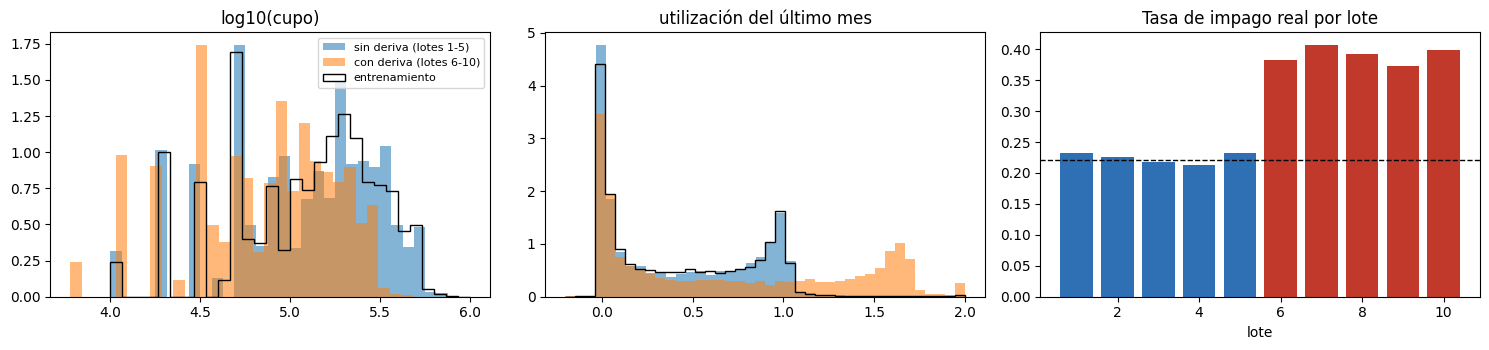

In [3]:
d = lotes.merge(targets[[ID, 'lote_id', TARGET]], on=[ID, 'lote_id'])
d = d[d.registro_corrupto == 0]
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for k, g in d.groupby('deriva_inducida'):
    lab = 'con deriva (lotes 6-10)' if k else 'sin deriva (lotes 1-5)'
    ax[0].hist(np.log10(g.limit_bal), bins=30, alpha=.55, density=True, label=lab)
    ax[1].hist(g.util_m1.clip(-0.2, 2), bins=40, alpha=.55, density=True, label=lab)
ax[0].hist(np.log10(train.limit_bal), bins=30, histtype='step', color='k', density=True, label='entrenamiento')
ax[1].hist(train.util_m1.clip(-0.2, 2), bins=40, histtype='step', color='k', density=True, label='entrenamiento')
ax[0].set_title('log10(cupo)'); ax[1].set_title('utilización del último mes'); ax[0].legend(fontsize=8)
t = d.groupby(['lote_id']).agg(tasa=(TARGET, 'mean'))
ax[2].bar(t.index, t.tasa, color=['#2f6fb3' if l < 6 else '#c0392b' for l in t.index]); ax[2].axhline(train[TARGET].mean(), color='k', ls='--', lw=1)
ax[2].set_title('Tasa de impago real por lote'); ax[2].set_xlabel('lote')
plt.tight_layout(); import os; os.makedirs('../docs/img', exist_ok=True); plt.savefig('../docs/img/sim_deriva_inducida.png', dpi=130); plt.show()

## 3. Umbrales de PSI: piso de ruido

Se calcula el PSI entre entrenamiento y 200 submuestras aleatorias de 600 clientes del propio entrenamiento. En esas submuestras no hay deriva por construcción, así que su PSI es puro ruido de muestreo para un lote de este tamaño.

Si el percentil 99 de ese ruido queda muy por debajo de 0,10, los cortes estándar se sostienen en este proyecto:
- **0,10 (moderada).** Un PSI mayor no se explica por el tamaño del lote.
- **0,25 (alta).** El cambio de distribución es grande.

In [4]:
piso = deriva.piso_ruido_psi(train, feats, n=600, repeticiones=200)
piso.to_csv('../docs/piso_ruido_psi.csv', index=False)
print(f"PSI por ruido de muestreo (n=600): mediana del p99 entre features = {piso.psi_p99.median():.3f}; "
      f"máximo p99 = {piso.psi_p99.max():.3f} ({piso.loc[piso.psi_p99.idxmax(), 'feature']})")
piso.sort_values('psi_p99', ascending=False).head(8).round(3)

PSI por ruido de muestreo (n=600): mediana del p99 entre features = 0.032; máximo p99 = 0.045 (n_overlimit_months_6m)


,feature,psi_p50,psi_p99
38,n_overlimit_months_6m,0.009,0.045
14,util_m2,0.013,0.042
23,pay_status_m5,0.012,0.042
15,pay_status_m3,0.013,0.041
31,max_delay_6m,0.013,0.041
39,n_credit_balance_months_6m,0.012,0.039
6,months_with_credit_balance,0.012,0.039
7,pay_status_m1,0.014,0.039


**Conclusión.** El PSI más alto que produce el puro azar en un lote de 600 clientes queda por debajo del umbral moderado de 0,10. Por eso se fijan estos umbrales:
- **PSI > 0,25:** alerta de severidad alta.
- **PSI entre 0,10 y 0,25:** aviso moderado. Solo genera alerta si aparece en 3 o más features a la vez.

KS y chi-cuadrado solo confirman la decisión del PSI (p < 0,01). Con 600 clientes frente a 24.000, esas pruebas declaran "significativas" diferencias mínimas, así que no deciden la alerta por sí solas.

**Siguiente paso:** ejecutar en Kestra `usfq.proyecto_final.produccion_lotes`, con los lotes 1 a 10 y `cierre = true`. Cuando se dispare un reentrenamiento, aprobar o rechazar en la pausa `aprobacion`. Después, correr el notebook 07.